# Reconstruction error of the SubCellSpace CVAE

This notebook measures how well the CVAE reconstructs its input, puts that number on a scale,
and tests whether reconstruction error tracks what the embedding is used for. Its last cell
draws Supp. Fig. 1.

**The reconstruction error.** On the 44,706 held-out simulated images the per-pixel mean squared
error is **0.0081** on the transcript channel, the channel the training loss optimises, which
corresponds to **R² = 0.165**: the reconstruction accounts for about a sixth of the pixel
variance. It is reported per channel because the loss never optimises the DAPI channel, which
scores R² = −2.52, and a single number across both is dominated by it. Across both channels it
is 0.276 per pixel, which reproduces the value stored in the model's own validation history, so
the convention is the one the training code used.

**The size of the code sets that number.** Compressing a 10,000-pixel image into 15 numbers is a
~667× reduction. The best *linear* code of the same width, PCA-15, reaches R² = 0.172, and it
takes 100 components to reach 0.43. The decoder's native output is 26×26, enlarged to 100×100
by a parameter-free nearest-neighbour step, so every reconstruction contains exactly 676 distinct
values and even a perfect 26×26 summary would stop at R² = 0.67 (§1).

**Patterns whose reconstructions look alike stay separable in the latent.** A classifier
separates `cell-edge` from `extranuclear` at κ 0.34 from the input at the decoder's working
resolution, 0.49 from the reconstruction, and **0.56 from the 15-dimensional latent**; the
latent, the representation the method uses, is the most discriminative of the three in 14 of
15 pattern pairs. `pericellular` versus `perinuclear` separates at κ 0.945 in the latent (§2).

**Reconstruction error does not track representation quality.** Across 50 checkpoints of a
500-epoch run, reconstruction improves monotonically — 35 % better at epoch 500 than at epoch
40 — while the silhouette of the latent by pattern peaks at epoch 40 and then falls by **87 %**.
Training reconstruction loss correlates with the supervised pattern probe (r = −0.92) but
*anti*-correlates with silhouette (r = +0.25). Selecting a model by reconstruction error would
run to epoch 500; the representation metrics select roughly epoch 100, which is where the
published model stops (§3). The measures that track what the method is for are the ones the
paper reports: the pattern probe (κ 0.776) and gene-level detection against the APEX-seq and
small-intestine ground truth.

**Scope.** §1 is over the full held-out simulated split; §2 and §3 use a fixed,
pattern-stratified 7,998-image subsample of it. The 500-epoch run exists for the 2-channel model
only. The cached inputs read below are produced by `scripts/reconstruction/`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, torch
import matplotlib as mpl, matplotlib.pyplot as plt
from skimage.io import imread
warnings.filterwarnings("ignore")

import paths
DATA = paths.data("reconstruction")
FIG  = paths.figures("reconstruction")

# produced by scripts/reconstruction/measure_reconstruction.py
REC   = pd.read_csv(DATA / "recon_simulated.csv")
PCA_L = pd.read_csv(DATA / "pca_ladder.csv")
PAIRS = pd.read_csv(DATA / "pair_separability.csv")
SWEEP = pd.read_csv(DATA / "epoch_sweep_e500.csv").sort_values("epoch")
PCA_PROV   = json.load(open(DATA / "pca_provenance.json"))
SWEEP_PROV = json.load(open(DATA / "sweep_provenance.json"))

SURFACE, INK, INK_MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
ACC, WARN = "#1f77b4", "#d62728"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRIDC,
    "font.size":9,"axes.titlesize":10,"figure.dpi":120,
    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})

NAMED = [("cell-edge","extranuclear"), ("pericellular","perinuclear")]   # pairs whose reconstructions look alike
print(f"{len(REC):,} held-out images reconstructed")
print(f"  gene channel  MSE {REC.mse_gene.mean():.6f}/pixel   R2 median {REC.r2_gene.median():+.4f}")
print(f"  DAPI channel  MSE {REC.mse_dapi.mean():.6f}/pixel   R2 median {REC.r2_dapi.median():+.4f}")
print(f"  both channels MSE {(REC.mse_gene.mean()+REC.mse_dapi.mean())/2:.6f}/pixel"
      f"   <- the stored val_loss works out to 0.276, so the convention checks out")

44,706 held-out images reconstructed
  gene channel  MSE 0.008102/pixel   R2 median +0.1652
  DAPI channel  MSE 0.543832/pixel   R2 median -2.5214
  both channels MSE 0.275967/pixel   <- the stored val_loss works out to 0.276, so the convention checks out


## 1. The reconstruction error, and what it should be compared against

The model's own loss is a sum over pixels, channels and images (`reduction="sum"`), so it is
first divided back out to a per-pixel mean. Two things have to be said before a number is
quoted. The training loss optimises the **gene channel only** (`CVAE.py:180`), while the
validation loss covers **all** channels (`CVAE.py:290`) — so a single figure across channels
is dominated by one the model never tries to fit. And a bare MSE is uninterpretable, so it is
put on a ladder: the trivial prediction at one end, and at the other the best any 26×26
bottleneck could manage, which is what the decoder actually is.

                               label     r2    kind
       predict the global mean image 0.0475     ref
    best linear code, 5 dims (PCA-5) 0.1080     ref
              SubCellSpace (15 dims) 0.1652   model
  best linear code, 15 dims (PCA-15) 0.1716     ref
  best linear code, 30 dims (PCA-30) 0.2321     ref
  best linear code, 50 dims (PCA-50) 0.2978     ref
best linear code, 100 dims (PCA-100) 0.4305     ref
          ceiling of a 26x26 decoder 0.6745 ceiling

SubCellSpace explains 16.5% of pixel variance; the best linear code of the same width explains 17.2%.


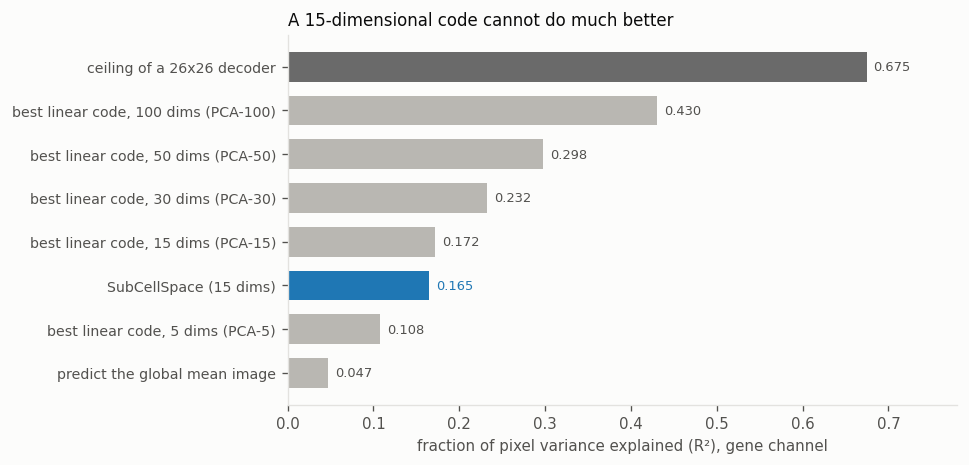

In [2]:
REF = PCA_L.copy()
REF["label"] = REF.code
CVAE_R2 = REC.r2_gene.median(); CVAE_MSE = REC.mse_gene.mean()
CEIL_R2 = REC.r2_ceiling.median()
rows = [dict(label="predict the global mean image", r2=float(REF.loc[REF.code=="global mean image","r2_median"]), kind="ref")]
for n in (5, 15, 30, 50, 100):
    rows.append(dict(label=f"best linear code, {n} dims (PCA-{n})",
                     r2=float(REF.loc[REF.code==f"PCA-{n}","r2_median"]), kind="ref"))
rows.append(dict(label="SubCellSpace (15 dims)", r2=float(CVAE_R2), kind="model"))
rows.append(dict(label="ceiling of a 26x26 decoder", r2=float(CEIL_R2), kind="ceiling"))
LAD = pd.DataFrame(rows).sort_values("r2").reset_index(drop=True)
print(LAD.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nSubCellSpace explains {CVAE_R2:.1%} of pixel variance; the best linear code of the "
      f"same width explains {float(REF.loc[REF.code=='PCA-15','r2_median']):.1%}.")


def fig_ladder():
    f, ax = plt.subplots(figsize=(7.2, 4.0))
    c = {"ref": "#b9b7b2", "model": ACC, "ceiling": "#6a6a6a"}
    ax.barh(np.arange(len(LAD)), LAD.r2, color=[c[k] for k in LAD.kind], height=.68)
    ax.set_yticks(np.arange(len(LAD))); ax.set_yticklabels(LAD.label, fontsize=8.5)
    for i, v in enumerate(LAD.r2):
        ax.text(v + .008, i, f"{v:.3f}", va="center", fontsize=7.8,
                color=ACC if LAD.kind[i] == "model" else INK_MUTED)
    ax.set_xlabel("fraction of pixel variance explained (R²), gene channel")
    ax.set_xlim(0, .78)
    ax.set_title("A 15-dimensional code cannot do much better", loc="left")
    f.savefig(FIG / "fig1_ladder.png", dpi=200, bbox_inches="tight")
    return f

fig_ladder();

Two observations. The CVAE explains about a sixth of the pixel variance, which is
what a 15-number code buys — the best *linear* code of the same width does no worse, and it
takes 100 dimensions to reach 0.43. Compressing a 10,000-pixel image to 15 values is a ~667×
reduction; nothing at that budget reproduces where individual transcripts sit. And the decoder
compounds it: its native output is 26×26, blown up to 100×100 by a parameter-free nearest
upsample, so even a perfect 26×26 summary would stop at R² 0.67.

## 2. Where the information separating those patterns lives

If the reconstruction cannot show what distinguishes two patterns, the question is whether
anything else can. The same classifier, with folds grouped by cell, is trained on three
representations of the same held-out images: the input at the decoder's own 26×26 working
resolution, the reconstruction at that resolution, and the 15-dimensional latent that the rest
of the method actually consumes.

space                         input_26  latent  recon_26
pair                                                    
cell-edge vs extranuclear       0.3398  0.5626    0.4941
extranuclear vs perinuclear     0.5363  0.6488    0.6803
cell-edge vs random             0.5791  0.6946    0.6404
extranuclear vs random          0.4906  0.8272    0.6052
cell-edge vs perinuclear        0.7417  0.8611    0.8587
perinuclear vs random           0.5971  0.9245    0.8390
cell-edge vs pericellular       0.6955  0.9287    0.8926
extranuclear vs pericellular    0.7073  0.9289    0.9115
pericellular vs perinuclear     0.8706  0.9446    0.9230
pericellular vs random          0.8244  0.9797    0.9498
intranuclear vs random          0.8827  0.9947    0.9789
cell-edge vs intranuclear       0.9650  0.9949    0.9856
extranuclear vs intranuclear    0.9593  0.9971    0.9872
intranuclear vs perinuclear     0.8818  0.9978    0.9745
intranuclear vs pericellular    0.9730  0.9993    0.9858

latent beats the reconstructio

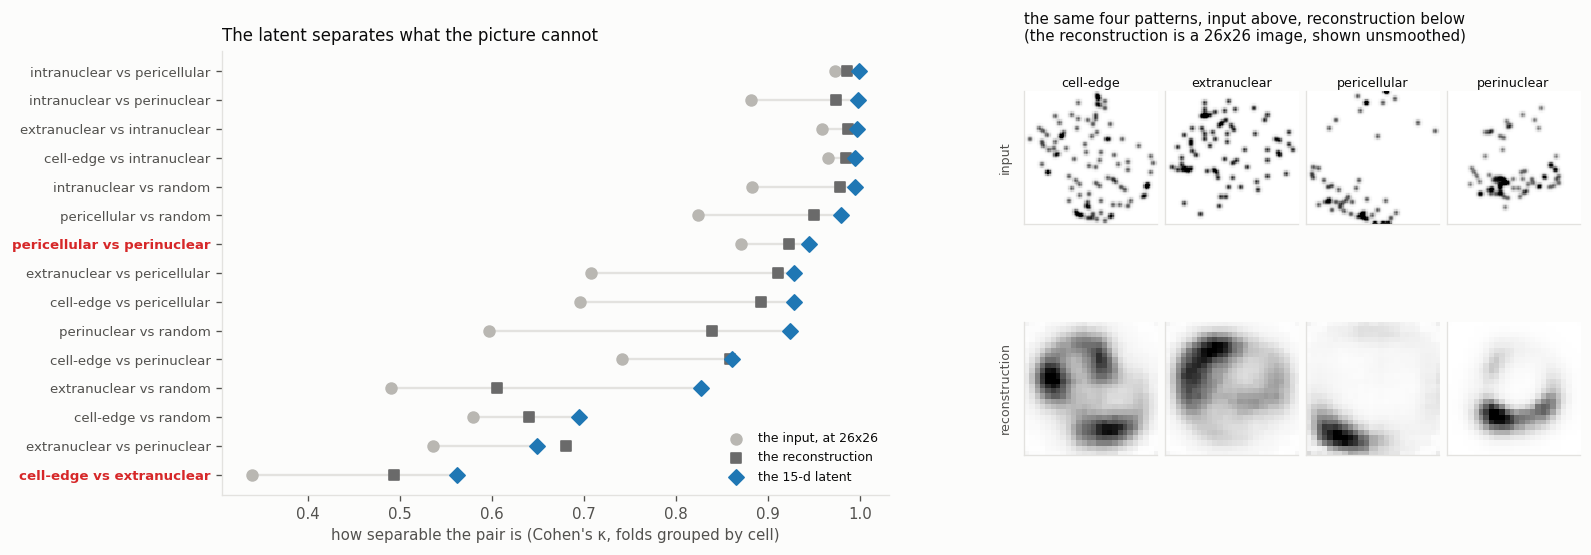

In [3]:
W = PAIRS.pivot(index="pair", columns="space", values="kappa")
W = W.loc[W.latent.sort_values().index]
named_lbl = [f"{a} vs {b}" for a, b in NAMED]
print(W.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nlatent beats the reconstruction in {int((W.latent > W.recon_26).sum())}/{len(W)} pairs; "
      f"the reconstruction beats the raw input in {int((W.recon_26 > W.input_26).sum())}/{len(W)}")
for lbl in named_lbl:
    r = W.loc[lbl]
    print(f"  {lbl:34s} input {r.input_26:.3f}  recon {r.recon_26:.3f}  latent {r.latent:.3f}")


def fig_pairs():
    f, axes = plt.subplots(1, 2, figsize=(14.6, 4.8),
                           gridspec_kw={"width_ratios": [1.2, 1], "wspace": 0.22})
    ax = axes[0]
    y = np.arange(len(W))
    for sp, mk, cl, lab in (("input_26", "o", "#b9b7b2", "the input, at 26x26"),
                            ("recon_26", "s", "#6a6a6a", "the reconstruction"),
                            ("latent", "D", ACC, "the 15-d latent")):
        ax.scatter(W[sp], y, marker=mk, s=42, color=cl, zorder=3, label=lab)
    for i in y:
        ax.plot([W.input_26.iloc[i], W.latent.iloc[i]], [i, i], color=GRIDC, lw=1.4, zorder=1)
    ax.set_yticks(y); ax.set_yticklabels(W.index, fontsize=8)
    for t, lbl in zip(ax.get_yticklabels(), W.index):
        if lbl in named_lbl: t.set_fontweight("bold"); t.set_color(WARN)
    ax.set_xlabel("how separable the pair is (Cohen's κ, folds grouped by cell)")
    ax.legend(fontsize=7.5, loc="lower right")
    ax.set_title("The latent separates what the picture cannot", loc="left")

    ax = axes[1]
    ax.axis("off")
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    # the checkpoint stores a CVAE instance; paths puts the repo root (CVAE.py) on sys.path
    cvae = torch.load(str(paths.MODEL), map_location=device)["cvae"].to(device).eval()
    # one held-out image per pattern, drawn with RandomState(101) over the held-out stems;
    # the four chosen stems and their images are stored with the data
    EX = pd.read_csv(DATA / "examples" / "example_stems.csv")
    pats = list(EX.pattern)
    gs = axes[1].get_subplotspec().subgridspec(2, len(pats), hspace=.08, wspace=.06,
                                               height_ratios=[1, 1])
    for j, (p, s) in enumerate(zip(EX.pattern, EX.stem)):
        g = imread(str(DATA / "examples" / f"{s}.tif")).astype(np.float32)
        d = imread(str(DATA / "examples" / f"{s}_DAPI.tif")).astype(np.float32)
        def mm(a):
            r = a.max() - a.min(); return (a - a.min()) / r if r > 0 else a * 0
        X = torch.from_numpy(np.stack([np.stack([mm(g), mm(d)])])).to(device)
        with torch.no_grad():
            _, mu, _ = cvae.embed(X); R = cvae.decode(mu).cpu().numpy()[0, 0]
        for row, img, lab in ((0, mm(g), "input"), (1, R, "reconstruction")):
            a = f.add_subplot(gs[row, j])
            # nearest, or matplotlib smooths away the very blockiness being demonstrated:
            # the reconstruction holds exactly 26x26 = 676 distinct values
            a.imshow(img, cmap="Greys", vmin=0, vmax=np.percentile(img, 99.5),
                     interpolation="nearest")
            a.set_xticks([]); a.set_yticks([])
            for sp in a.spines.values(): sp.set_color(GRIDC)
            if row == 0: a.set_title(p, fontsize=7.6, pad=3)
            if j == 0: a.set_ylabel(lab, fontsize=7.6)
    axes[1].set_title("the same four patterns, input above, reconstruction below\n"
                      "(the reconstruction is a 26x26 image, shown unsmoothed)",
                      loc="left", fontsize=9)
    f.savefig(FIG / "fig2_pairs.png", dpi=200, bbox_inches="tight")
    return f

fig_pairs();

The ordering is consistent: the latent separates a pair better than the
reconstruction does, and the reconstruction better than the input at the same resolution. The
model is not discarding the distinction — it is concentrating it somewhere the picture cannot
show it. `cell-edge` versus `extranuclear` is the hardest pair in the set by every measure, and
notably it is already hard in the input, so a reconstruction that blurs the two is reproducing
a genuine similarity in the data rather than inventing one. The other pair whose
reconstructions look alike, `pericellular` versus `perinuclear`, is separated at κ 0.945.

## 3. Does reconstruction error track what the model is for?

One way to test whether reconstruction error measures efficacy is to watch it against
representation quality over training. This uses a 500-epoch run of the same 2-channel architecture, scoring
50 checkpoints on a fixed held-out subsample: the loss comes out of each checkpoint's own
history, and the two representation metrics are recomputed from the encoded latent.

Absolute silhouette values here are not comparable with the published ablation table, which
subsamples differently; the trajectory is the point.

epochs covered: 10-500 (50 checkpoints, 2-channel run)
  best reconstruction (train)  epoch 500   0.007621/px
  best held-out val loss       epoch 270   0.264550/px
  best silhouette              epoch 40   +0.1630
  best pattern kappa           epoch 100   0.7285

from the best-silhouette epoch to epoch 500: reconstruction -34.6%, silhouette -86.8%
correlation across checkpoints, reconstruction loss vs silhouette: +0.254   vs kappa: -0.924


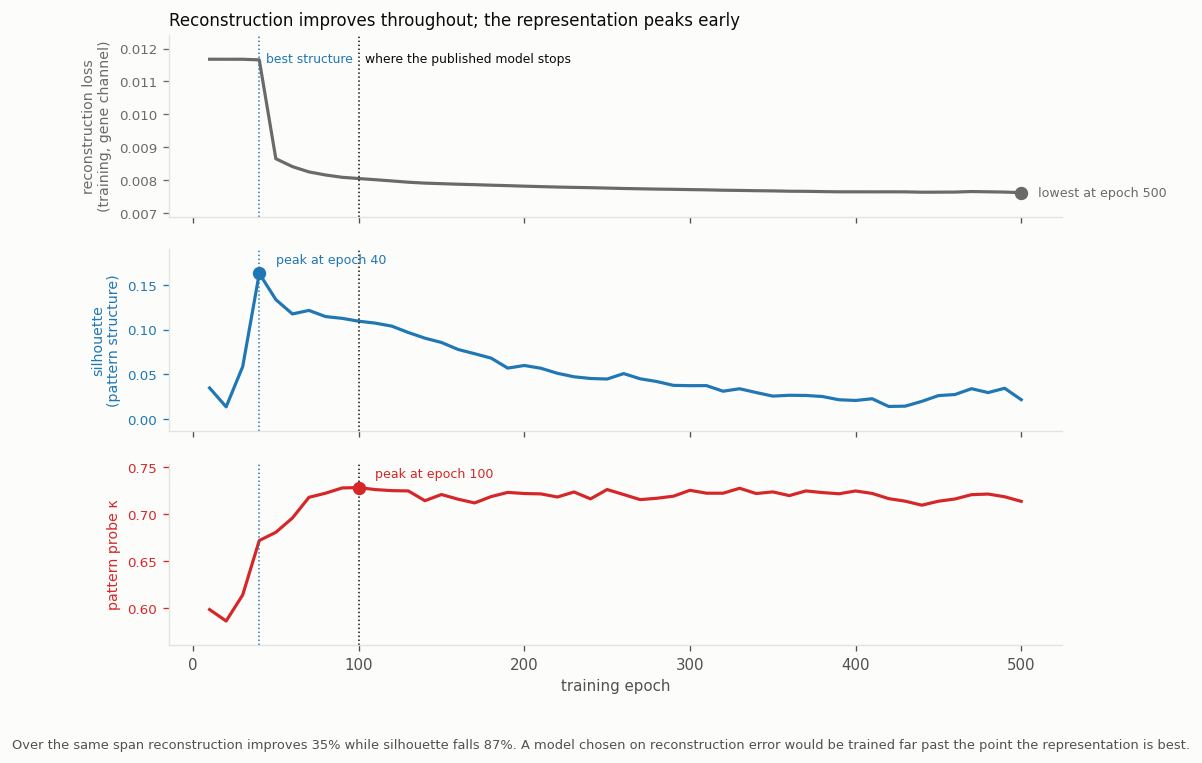

In [4]:
S = SWEEP
best_sil = S.loc[S.silhouette.idxmax()]; best_kap = S.loc[S.kappa.idxmax()]
best_rec = S.loc[S.train_recon_per_px.idxmin()]; best_val = S.loc[S.heldout_val_per_px.idxmin()]
print(f"epochs covered: {S.epoch.min()}-{S.epoch.max()} ({len(S)} checkpoints, 2-channel run)")
print(f"  best reconstruction (train)  epoch {int(best_rec.epoch)}   {best_rec.train_recon_per_px:.6f}/px")
print(f"  best held-out val loss       epoch {int(best_val.epoch)}   {best_val.heldout_val_per_px:.6f}/px")
print(f"  best silhouette              epoch {int(best_sil.epoch)}   {best_sil.silhouette:+.4f}")
print(f"  best pattern kappa           epoch {int(best_kap.epoch)}   {best_kap.kappa:.4f}")
print(f"\nfrom the best-silhouette epoch to epoch {int(S.epoch.max())}: "
      f"reconstruction {100*(S.train_recon_per_px.iloc[-1]/best_sil.train_recon_per_px-1):+.1f}%, "
      f"silhouette {100*(S.silhouette.iloc[-1]/best_sil.silhouette-1):+.1f}%")
print(f"correlation across checkpoints, reconstruction loss vs silhouette: "
      f"{np.corrcoef(S.train_recon_per_px, S.silhouette)[0,1]:+.3f}   vs kappa: "
      f"{np.corrcoef(S.train_recon_per_px, S.kappa)[0,1]:+.3f}")


def fig_sweep():
    """Three panels on a shared epoch axis rather than twin y-axes: silhouette and kappa
    live on very different scales, and an inverted loss axis invites misreading."""
    f, axes = plt.subplots(3, 1, figsize=(9.6, 6.6), sharex=True,
                           gridspec_kw={"hspace": .18})
    marks = [(int(best_sil.epoch), ACC, "best structure"),
             (100, INK, "where the published model stops")]
    series = [(axes[0], S.train_recon_per_px, "#6a6a6a",
               "reconstruction loss\n(training, gene channel)", True),
              (axes[1], S.silhouette, ACC, "silhouette\n(pattern structure)", False),
              (axes[2], S.kappa, WARN, "pattern probe \u03ba", False)]
    for ax, y, c, lab, lower_better in series:
        ax.plot(S.epoch, y, color=c, lw=1.9)
        ax.set_ylabel(lab, fontsize=8.5, color=c)
        ax.tick_params(axis="y", colors=c, labelsize=8)
        ax.margins(y=.18)
        for e, mc, _ in marks:
            ax.axvline(e, color=mc, lw=.9, ls=":")
        best = y.idxmin() if lower_better else y.idxmax()
        ax.plot(S.epoch[best], y[best], "o", ms=7, color=c, zorder=4)
        ax.annotate(f"{'lowest' if lower_better else 'peak'} at epoch {int(S.epoch[best])}",
                    (S.epoch[best], y[best]), xytext=(10, -2 if lower_better else 6),
                    textcoords="offset points", fontsize=7.6, color=c)
    for e, mc, lab in marks:
        axes[0].annotate(lab, (e, axes[0].get_ylim()[1]), xytext=(4, -10),
                         textcoords="offset points", fontsize=7.4, color=mc, va="top")
    axes[2].set_xlabel("training epoch")
    axes[0].set_title("Reconstruction improves throughout; the representation peaks early",
                      loc="left")
    f.text(.5, -.02,
           f"Over the same span reconstruction improves {abs(100*(S.train_recon_per_px.iloc[-1]/best_sil.train_recon_per_px-1)):.0f}% "
           f"while silhouette falls {abs(100*(S.silhouette.iloc[-1]/best_sil.silhouette-1)):.0f}%. "
           "A model chosen on reconstruction error would be trained far past the point the "
           "representation is best.",
           ha="center", fontsize=7.8, color=INK_MUTED)
    f.savefig(FIG / "fig3_sweep.png", dpi=200, bbox_inches="tight")
    return f

fig_sweep();

## In short

The reconstruction error is 0.0081 per pixel, R² 0.165, on the channel the loss optimises. That
is what a 15-number code buys — the best linear code of the same width does no better — and the
decoder's 26×26 native output caps any such model at 0.67. The reconstructions in Figure 1C are
therefore coarse by construction. What the reconstruction cannot show, though, the latent still
carries: the same pairs separate better in the 15-dimensional code than in either the reconstruction or the input.

Reconstruction error should not be used to judge this model. Over 500 epochs it improves
steadily while the latent's cluster structure degrades by 87 %, so a model chosen on
reconstruction would be a worse representation. That is why the paper reports classification and
detection measures, with the reconstruction error stated alongside them.

## Supp. Fig. 1

The page as published, drawn from the cached inputs loaded at the top of this notebook.

1_reconstruction_error_total


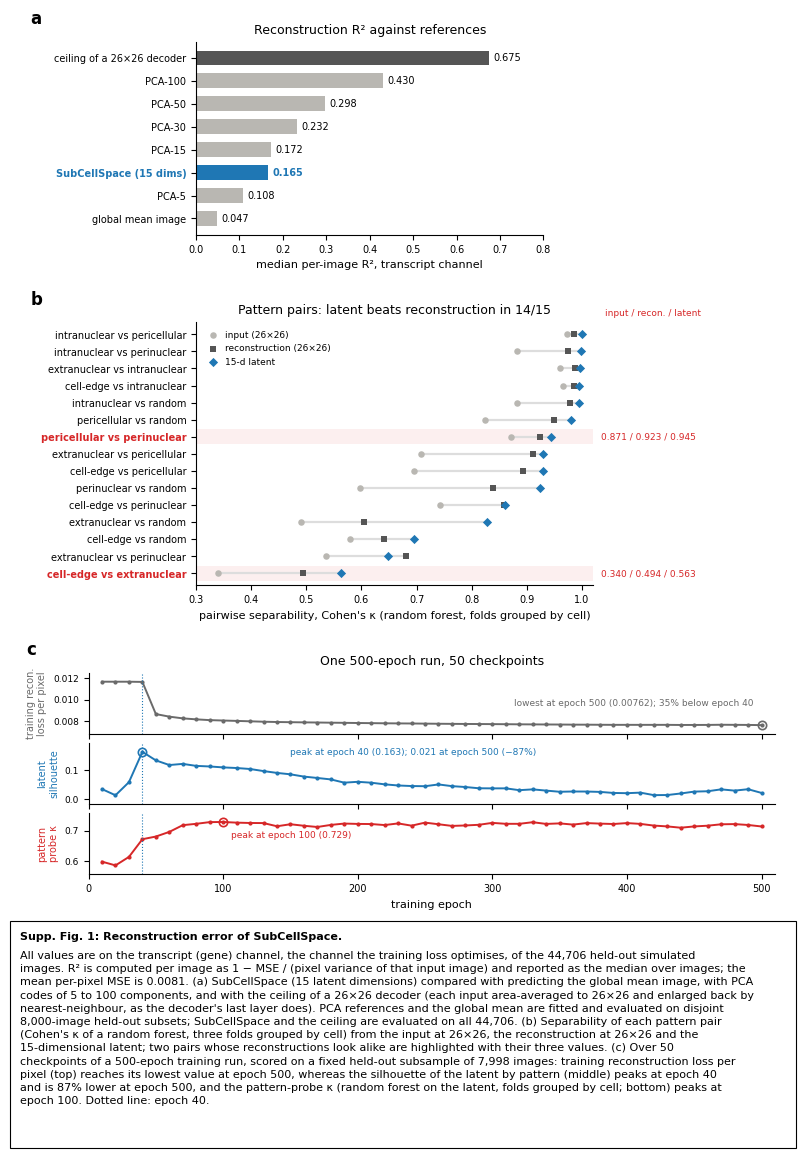

In [5]:
# Supp. Fig. 1, drawn from the same cached inputs loaded above.
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from supp_style import new_page, panel_letter, caption_box, save_page, COL

PCA = PCA_L
SW = SWEEP.sort_values("epoch").reset_index(drop=True)
PROV = PCA_PROV
N_SWEEP = int(SWEEP_PROV["n_eval_images"])

N_IMG = len(REC)
assert N_IMG == 44706
assert PROV["n_fit"] == PROV["n_eval"] == 8000
assert len(SW) == 50 and SW.epoch.max() == 500

CVAE_R2 = REC.r2_gene.median()
CVAE_MSE = REC.mse_gene.mean()
CEIL_R2 = REC.r2_ceiling.median()
PAGE_NAMED = ["cell-edge vs extranuclear", "pericellular vs perinuclear"]
ACC, GREY, DARK, WARN = "#1f77b4", "#b9b7b2", "#555555", "#d62728"

fig = new_page()

# ---------------------------------------------------------------- a: R2 ladder
rows = [("global mean image", float(PCA.loc[PCA.code == "global mean image", "r2_median"].iloc[0]), "ref")]
for n in (5, 15, 30, 50, 100):
    rows.append((f"PCA-{n}", float(PCA.loc[PCA.code == f"PCA-{n}", "r2_median"].iloc[0]), "ref"))
rows.append(("SubCellSpace (15 dims)", float(CVAE_R2), "model"))
rows.append(("ceiling of a 26×26 decoder", float(CEIL_R2), "ceil"))
lad = sorted(rows, key=lambda r: r[1])
ax_a = fig.add_axes([0.25, 0.795, 0.42, 0.165])
y = np.arange(len(lad))
cmap = {"ref": GREY, "model": ACC, "ceil": DARK}
ax_a.barh(y, [r[1] for r in lad], color=[cmap[r[2]] for r in lad], height=0.65)
for yi, (lab, v, k) in zip(y, lad):
    ax_a.text(v + 0.01, yi, f"{v:.3f}", va="center", fontsize=7,
              color=ACC if k == "model" else "black", weight="bold" if k == "model" else "normal")
ax_a.set_yticks(y)
ax_a.set_yticklabels([r[0] for r in lad], fontsize=7)
for t, r in zip(ax_a.get_yticklabels(), lad):
    if r[2] == "model":
        t.set_color(ACC); t.set_fontweight("bold")
ax_a.set_xlim(0, 0.8)
ax_a.set_xlabel("median per-image R², transcript channel")
ax_a.set_title("Reconstruction R² against references")
ax_a.spines[["top", "right"]].set_visible(False)
panel_letter(fig, ax_a, "a", dx=-0.20)

# ---------------------------------------------------------------- b: pair separability
Wd = PAIRS.pivot(index="pair", columns="space", values="kappa")
Wd = Wd.loc[Wd.latent.sort_values(ascending=False).index]
n_latent_wins = int((Wd.latent > Wd.recon_26).sum())
assert len(Wd) == 15
ax_c = fig.add_axes([0.25, 0.495, 0.48, 0.225])
yc = np.arange(len(Wd))[::-1]
for yi, (_, r) in zip(yc, Wd.iterrows()):
    lo, hi = r[["input_26", "recon_26", "latent"]].min(), r[["input_26", "recon_26", "latent"]].max()
    ax_c.plot([lo, hi], [yi, yi], color="#dddddd", lw=1.6, zorder=1)
spaces = [("input_26", "o", GREY, "input (26×26)"),
          ("recon_26", "s", DARK, "reconstruction (26×26)"),
          ("latent", "D", ACC, "15-d latent")]
for sp, mk, c, lab in spaces:
    ax_c.scatter(Wd[sp], yc, marker=mk, s=22, color=c, zorder=3, label=lab, linewidths=0)
ax_c.set_yticks(yc)
ax_c.set_yticklabels(Wd.index, fontsize=7)
for t, lbl in zip(ax_c.get_yticklabels(), Wd.index):
    if lbl in PAGE_NAMED:
        t.set_fontweight("bold"); t.set_color(WARN)
for yi, lbl in zip(yc, Wd.index):
    if lbl in PAGE_NAMED:
        r = Wd.loc[lbl]
        ax_c.axhspan(yi - 0.45, yi + 0.45, color=WARN, alpha=0.07, zorder=0, lw=0)
        ax_c.text(1.02, yi, f"{r.input_26:.3f} / {r.recon_26:.3f} / {r.latent:.3f}",
                  va="center", fontsize=6.5, color=WARN, transform=ax_c.get_yaxis_transform())
ax_c.set_xlim(0.3, 1.02)
ax_c.set_ylim(-0.7, len(Wd) - 0.3)
ax_c.set_xlabel("pairwise separability, Cohen's κ (random forest, folds grouped by cell)")
ax_c.set_title(f"Pattern pairs: latent beats reconstruction in {n_latent_wins}/{len(Wd)}")
ax_c.legend(loc="upper left", frameon=False, fontsize=6.5, handletextpad=0.3)
ax_c.spines[["top", "right"]].set_visible(False)
fig.text(0.745, 0.495 + 0.225 + 0.006, "input / recon. / latent", fontsize=6.5, color=WARN)
panel_letter(fig, ax_c, "b", dx=-0.20)

# ---------------------------------------------------------------- c: 500-epoch sweep
i_sil = SW.silhouette.idxmax(); i_kap = SW.kappa.idxmax(); i_rec = SW.train_recon_per_px.idxmin()
e_sil, e_kap, e_rec = (int(SW.epoch[i]) for i in (i_sil, i_kap, i_rec))
sil_drop = 1 - SW.silhouette.iloc[-1] / SW.silhouette[i_sil]
rec_drop = 1 - SW.train_recon_per_px.iloc[-1] / SW.train_recon_per_px[i_sil]
series = [("train_recon_per_px", "#6a6a6a", "training recon.\nloss per pixel", True),
          ("silhouette", ACC, "latent\nsilhouette", False),
          ("kappa", WARN, "pattern\nprobe κ", False)]
axes_d = []
h, gap, top = 0.052, 0.008, 0.42
for k, (col, c, lab, low) in enumerate(series):
    ax = fig.add_axes([0.12, top - (k + 1) * h - k * gap, 0.83, h])
    yv = SW[col]
    ax.plot(SW.epoch, yv, color=c, lw=1.4, marker="o", ms=2)
    i = yv.idxmin() if low else yv.idxmax()
    ax.plot(SW.epoch[i], yv[i], "o", ms=6, mfc="none", mec=c, mew=1.2, zorder=4)
    ax.axvline(e_sil, color=ACC, ls=":", lw=0.8)
    if col == "train_recon_per_px":
        txt = f"lowest at epoch {int(SW.epoch[i])} ({yv[i]:.5f}); {rec_drop:.0%} below epoch {e_sil}"
        ax.annotate(txt, (SW.epoch[i], yv[i]), xytext=(-6, 14), textcoords="offset points",
                    ha="right", fontsize=6.5, color=c)
    elif col == "silhouette":
        txt = (f"peak at epoch {int(SW.epoch[i])} ({yv[i]:.3f}); "
               f"{SW.silhouette.iloc[-1]:.3f} at epoch 500 (−{sil_drop:.0%})")
        ax.text(150, yv[i], txt, ha="left", va="center", fontsize=6.5, color=c)
    else:
        txt = f"peak at epoch {int(SW.epoch[i])} ({yv[i]:.3f})"
        ax.annotate(txt, (SW.epoch[i], yv[i]), xytext=(6, -6), textcoords="offset points",
                    ha="left", va="top", fontsize=6.5, color=c)
    ax.set_ylabel(lab, fontsize=7, color=c)
    ax.tick_params(axis="y", labelsize=6.5)
    ax.margins(y=0.2)
    ax.set_xlim(0, 510)
    ax.spines[["top", "right"]].set_visible(False)
    if k < 2:
        ax.tick_params(labelbottom=False)
    axes_d.append(ax)
axes_d[0].set_title(f"One 500-epoch run, {len(SW)} checkpoints")
axes_d[-1].set_xlabel("training epoch")
panel_letter(fig, axes_d[0], "c", dx=-0.075)

cap_top = top - 3 * h - 2 * gap - 0.04
caption_box(fig, cap_top,
    "Supp. Fig. 1: Reconstruction error of SubCellSpace.",
    f"All values are on the transcript (gene) channel, the channel the training loss optimises, of the "
    f"{N_IMG:,} held-out simulated images. R² is computed per image as 1 − MSE / (pixel variance of that input "
    f"image) and reported as the median over images; the mean per-pixel MSE is {CVAE_MSE:.4f}. "
    f"(a) SubCellSpace (15 latent dimensions) compared with predicting the global mean image, with PCA codes of 5 to "
    f"100 components, and with the ceiling of a 26×26 decoder (each input area-averaged to 26×26 and "
    f"enlarged back by nearest-neighbour, as the decoder's last layer does). PCA references and the global mean are fitted and evaluated on "
    f"disjoint {PROV['n_fit']:,}-image held-out subsets; SubCellSpace and the ceiling are evaluated on all "
    f"{N_IMG:,}. (b) Separability of each pattern "
    f"pair (Cohen's κ of a random forest, three folds grouped by cell) from the input at 26×26, the "
    f"reconstruction at 26×26 and the 15-dimensional latent; two pairs whose reconstructions look alike are highlighted "
    f"with their three values. (c) Over 50 checkpoints of a 500-epoch training run, scored on a fixed held-out "
    f"subsample of {N_SWEEP:,} images: training reconstruction loss per pixel (top) reaches its lowest value at epoch {e_rec}, whereas "
    f"the silhouette of the latent by pattern (middle) peaks at epoch {e_sil} and is {sil_drop:.0%} lower at "
    f"epoch 500, and the pattern-probe κ (random forest on the latent, folds grouped by cell; bottom) peaks at "
    f"epoch {e_kap}. Dotted line: epoch {e_sil}.",
    width_chars=128, fontsize=8)
print(save_page(fig, "1_reconstruction_error_total").name)
fig
